# Probability Calibration and Risk Stratification

## Adaptive Hospital Intelligence Platform

### Objective

The classification model can rank patients according to their predicted
30-day readmission risk. However, predicted probabilities should not
automatically be interpreted as real-world clinical risk probabilities.

This notebook evaluates probability calibration and investigates whether
calibration improves the reliability of predicted probabilities.

The analysis will:

1. Evaluate the uncalibrated XGBoost probability estimates.
2. Generate a calibration curve.
3. Calculate the Brier score.
4. Compare predicted probabilities with observed readmission rates.
5. Apply probability calibration where appropriate.
6. Define interpretable risk strata for use by the application layer.

> This system is a portfolio/research prototype and is not a clinically
> validated decision-support system.

## 1. Setup and Imports

In [12]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    brier_score_loss,
    roc_auc_score,
    average_precision_score
)

from sklearn.calibration import calibration_curve

# Allow imports from the project root
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\nolee\Adaptive Hospital Intelligence Platform


## 2. Reconstruct the Modeling Dataset

The same preprocessing and patient-level splitting strategy used during
model development is reproduced here to prevent patient leakage and maintain
consistency with previous experiments.

In [13]:
DATA_PATH = Path("../data/processed/clinical_features.csv")

df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 101,766
Columns: 29


,patient_id,encounter_id,age_midpoint,gender,race,admission_type,admission_source,discharge_disposition,length_of_stay,previous_inpatient_visits,...,hba1c_result,glucose_result,insulin_status,diabetes_medication,readmitted_30_days,primary_diagnosis_category,secondary_diagnosis_category,tertiary_diagnosis_category,total_previous_visits,has_previous_inpatient_visit
0,8222157,2278392,5,Female,Caucasian,Unmapped:6,Physician Referral,Not Mapped,1,0,...,NaN,NaN,No,No,False,Diabetes,Other,Other,0,0
1,55629189,149190,15,Female,Caucasian,Emergency,Emergency Room,Discharged to home,3,0,...,NaN,NaN,Up,Yes,False,Endocrine,Diabetes,Endocrine,0,0
2,86047875,64410,25,Female,AfricanAmerican,Emergency,Emergency Room,Discharged to home,2,1,...,NaN,NaN,No,Yes,False,Pregnancy,Diabetes,Supplementary,3,1
3,82442376,500364,35,Male,Caucasian,Emergency,Emergency Room,Discharged to home,2,0,...,NaN,NaN,Up,Yes,False,Infectious,Diabetes,Circulatory,0,0
4,42519267,16680,45,Male,Caucasian,Emergency,Emergency Room,Discharged to home,1,0,...,NaN,NaN,Steady,Yes,False,Neoplasms,Neoplasms,Diabetes,0,0


In [14]:
# Target variable distribution

TARGET = "readmitted_30_days"

print("Target distribution:")
print(df[TARGET].value_counts())

print("\nTarget distribution (%):")
print(
    df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target distribution:
readmitted_30_days
False    90409
True     11357
Name: count, dtype: int64

Target distribution (%):
readmitted_30_days
False    88.84
True     11.16
Name: proportion, dtype: float64


In [56]:
# Define model features and prepare input and target variables

model_features = [
    "age_midpoint",
    "gender",
    "race",
    "admission_type",
    "admission_source",
    "discharge_disposition",
    "length_of_stay",
    "previous_inpatient_visits",
    "previous_outpatient_visits",
    "previous_emergency_visits",
    "diagnosis_count",
    "lab_procedure_count",
    "procedure_count",
    "medication_count",
    "hba1c_result",
    "glucose_result",
    "insulin_status",
    "diabetes_medication",
    "primary_diagnosis_category",
    "secondary_diagnosis_category",
    "tertiary_diagnosis_category",
    "total_previous_visits",
    "has_previous_inpatient_visit",
]

# Exclude death-related discharges from the modeling population

print("Encounters before filtering:", len(df))

death_mask = (
    df["discharge_disposition"]
    .astype(str)
    .str.contains("Expired", case=False, na=False)
)

print("Death-related encounters:", death_mask.sum())

df = df.loc[~death_mask].copy()

print("Encounters after filtering:", len(df))

# Prepare modeling inputs, target, and patient groups

X = df[model_features].copy()
y = df[TARGET].astype(int)
groups = df["patient_id"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique patients:", groups.nunique())

Encounters before filtering: 100114
Death-related encounters: 0
Encounters after filtering: 100114
X shape: (100114, 23)
y shape: (100114,)
Unique patients: 70439


In [58]:
# Validate the filtered modeling dataset

X = df[model_features].copy()
y = df[TARGET].astype(int)
groups = df["patient_id"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique patients:", groups.nunique())

assert X.shape[1] == len(model_features), "Unexpected number of model features"
assert len(X) == len(y) == len(groups), "Model inputs have different row counts"
assert X.index.equals(y.index) and X.index.equals(groups.index), (
    "Model inputs are not aligned by row"
)
assert not df["discharge_disposition"].astype(str).str.contains(
    "Expired", case=False, na=False
).any(), "Death-related encounters remain in the modeling dataset"

print("\n✓ Modeling dataset successfully reconstructed.")

X shape: (100114, 23)
y shape: (100114,)
Unique patients: 70439

✓ Modeling dataset successfully reconstructed.


In [17]:
# Reproducibility
RANDOM_STATE = 42

print("Random state:", RANDOM_STATE)

Random state: 42


In [59]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups=groups
    )
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_groups = groups.iloc[train_idx].copy()
test_groups = groups.iloc[test_idx].copy()

print("Training encounters:", len(X_train))
print("Testing encounters:", len(X_test))

print("\nTraining patients:", train_groups.nunique())
print("Testing patients:", test_groups.nunique())

Training encounters: 80039
Testing encounters: 20075

Training patients: 56351
Testing patients: 14088


In [19]:
# Verify that patients do not appear in both datasets

train_patient_ids = set(train_groups)
test_patient_ids = set(test_groups)

overlapping_patients = train_patient_ids.intersection(
    test_patient_ids
)

print("Training patients:", len(train_patient_ids))
print("Testing patients:", len(test_patient_ids))
print("Overlapping patients:", len(overlapping_patients))

assert len(overlapping_patients) == 0, (
    "Data leakage detected: patients appear in both sets!"
)

print("Patient-level split verification passed!")

Training patients: 57214
Testing patients: 14304
Overlapping patients: 0
Patient-level split verification passed!


## 4. Create a Dedicated Calibration Set

Probability calibration requires data that was not used to fit the predictive
model.

The original training partition is therefore divided again at the patient
level into:

- **Model-training set** — used to fit the XGBoost model.
- **Calibration set** — used to evaluate and calibrate predicted probabilities.
- **Test set** — remains completely untouched until final evaluation.

Patient-level splitting prevents encounters belonging to the same patient
from appearing in multiple subsets.

In [60]:
# Split the original training partition into:
# 80% model-training data and 20% calibration data

calibration_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

model_train_idx, calibration_idx = next(
    calibration_splitter.split(
        X_train,
        y_train,
        groups=train_groups
    )
)

X_model_train = X_train.iloc[model_train_idx].copy()
X_cal = X_train.iloc[calibration_idx].copy()

y_model_train = y_train.iloc[model_train_idx].copy()
y_cal = y_train.iloc[calibration_idx].copy()

groups_model_train = train_groups.iloc[model_train_idx].copy()
groups_cal = train_groups.iloc[calibration_idx].copy()

print("MODEL-TRAINING SET")
print("------------------")
print("Encounters:", len(X_model_train))
print("Patients:", groups_model_train.nunique())
print("Positive rate:", round(y_model_train.mean(), 4))

print("\nCALIBRATION SET")
print("---------------")
print("Encounters:", len(X_cal))
print("Patients:", groups_cal.nunique())
print("Positive rate:", round(y_cal.mean(), 4))

print("\nTEST SET")
print("--------")
print("Encounters:", len(X_test))
print("Patients:", test_groups.nunique())
print("Positive rate:", round(y_test.mean(), 4))

MODEL-TRAINING SET
------------------
Encounters: 63949
Patients: 45080
Positive rate: 0.1128

CALIBRATION SET
---------------
Encounters: 16090
Patients: 11271
Positive rate: 0.1142

TEST SET
--------
Encounters: 20075
Patients: 14088
Positive rate: 0.1148


In [61]:
# Verify patient separation across all three datasets

model_patients = set(groups_model_train)
calibration_patients = set(groups_cal)
test_patients = set(test_groups)

print("PATIENT SEPARATION VERIFICATION")
print("--------------------------------")

print(
    "Model training vs Calibration:",
    len(model_patients & calibration_patients)
)

print(
    "Model training vs Test:",
    len(model_patients & test_patients)
)

print(
    "Calibration vs Test:",
    len(calibration_patients & test_patients)
)

assert model_patients.isdisjoint(calibration_patients)
assert model_patients.isdisjoint(test_patients)
assert calibration_patients.isdisjoint(test_patients)

print("\nAll patient separation checks passed!")

PATIENT SEPARATION VERIFICATION
--------------------------------
Model training vs Calibration: 0
Model training vs Test: 0
Calibration vs Test: 0

All patient separation checks passed!


In [21]:
# Verify that patients do not cross dataset boundaries

model_train_patients = set(groups_model_train)
calibration_patients = set(groups_cal)
test_patients = set(test_groups)

train_cal_overlap = model_train_patients.intersection(calibration_patients)
train_test_overlap = model_train_patients.intersection(test_patients)
cal_test_overlap = calibration_patients.intersection(test_patients)

print("PATIENT-LEVEL LEAKAGE CHECK")
print("---------------------------")
print("Model train ↔ Calibration:", len(train_cal_overlap))
print("Model train ↔ Test:", len(train_test_overlap))
print("Calibration ↔ Test:", len(cal_test_overlap))

assert len(train_cal_overlap) == 0
assert len(train_test_overlap) == 0
assert len(cal_test_overlap) == 0

print("\n✓ All three datasets are patient-independent.")

PATIENT-LEVEL LEAKAGE CHECK
---------------------------
Model train ↔ Calibration: 0
Model train ↔ Test: 0
Calibration ↔ Test: 0

✓ All three datasets are patient-independent.


## 5. Train the Uncalibrated XGBoost Model

The final Shallow XGBoost architecture selected in Notebook 03 is retrained
using only the dedicated model-training partition.

The calibration and test sets are excluded from model fitting.

This produces the **uncalibrated base model**, whose probability estimates
will be evaluated before applying probability calibration.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier

# Identify feature types
numeric_features = X_model_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_model_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numeric_features) + len(categorical_features))

Numeric features: 11
Categorical features: 12
Total features: 23


C:\Users\nolee\AppData\Local\Temp\ipykernel_32120\3640434249.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_model_train.select_dtypes(


In [23]:
# Create preprocessing pipelines for numeric and categorical features

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("✓ Preprocessing pipeline created.")

✓ Preprocessing pipeline created.


## 5. Train the Uncalibrated XGBoost Model

The Shallow XGBoost architecture selected during model development is
retrained using only the dedicated model-training partition.

The calibration set is excluded from model fitting and will be used only
for probability calibration. The test set remains completely untouched
until final evaluation.

This separation prevents information leakage between model training,
probability calibration, and final model evaluation.

In [24]:
# Calculate class imbalance weight using ONLY the model-training set

negative_count = (y_model_train == 0).sum()
positive_count = (y_model_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative cases:", negative_count)
print("Positive cases:", positive_count)
print("scale_pos_weight:", round(scale_pos_weight, 4))

Negative cases: 57817
Positive cases: 7329
scale_pos_weight: 7.8888


In [25]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

shallow_xgb = XGBClassifier(
    n_estimators=400,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

## 5. Rebuild the Final XGBoost Pipeline

The final model from Notebook 03 used separate preprocessing pipelines for
numerical and categorical variables.

To preserve consistency with the original model:

- categorical features are identified from their data types,
- numerical features are identified from their data types,
- missing numerical values are median-imputed,
- missing categorical values are mode-imputed,
- categorical variables are one-hot encoded,
- the same Shallow XGBoost configuration is used.

The model is fitted only on the model-training set. The calibration set and
test set remain untouched.

In [26]:
# Rebuilding the final xboost model

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

# Identify feature types using ONLY the model-training data
categorical_features_xgb = X_model_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical_features_xgb = X_model_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Categorical features:", len(categorical_features_xgb))
print("Numerical features:", len(numerical_features_xgb))
print("Total features:",
      len(categorical_features_xgb) + len(numerical_features_xgb))

Categorical features: 12
Numerical features: 11
Total features: 23


## 6. Building the Preprocessing Pipeline

The preprocessing pipeline mirrors the transformation strategy used by the
final XGBoost model in Notebook 03.

Numerical features:
- Missing values are replaced using the median.

Categorical features:
- Missing values are replaced using the most frequent category.
- Categories are converted into numerical indicator variables using one-hot encoding.
- Previously unseen categories are ignored safely during inference.

The preprocessing transformer is fitted only as part of the model pipeline
using the model-training dataset.

In [27]:
# Numerical preprocessing
numeric_transformer_xgb = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

# Categorical preprocessing
categorical_transformer_xgb = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

# Combine both preprocessing pipelines
preprocessor_xgb = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer_xgb,
            numerical_features_xgb
        ),
        (
            "cat",
            categorical_transformer_xgb,
            categorical_features_xgb
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 7. Training the Base Readmission Model

The Shallow XGBoost configuration selected in Notebook 03 is used as the
base predictive model.

Unlike the earlier experiment, the model is now trained only on the dedicated
model-training partition. The calibration and test datasets remain unseen.

This separation is necessary because the calibration dataset will later be
used exclusively to learn the mapping between raw model scores and calibrated
readmission probabilities.

In [28]:
# Class imbalance adjustment using ONLY the model-training data
negative_count = (y_model_train == 0).sum()
positive_count = (y_model_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative cases:", negative_count)
print("Positive cases:", positive_count)
print("scale_pos_weight:", round(scale_pos_weight, 4))

Negative cases: 57817
Positive cases: 7329
scale_pos_weight: 7.8888


In [62]:
#Constructing and training XGBoost model

# Recreate the selected Shallow XGBoost model
xgb_classifier = XGBClassifier(
    n_estimators=400,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Full preprocessing + ML pipeline
base_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_xgb),
        ("classifier", xgb_classifier)
    ]
)

print("Training base XGBoost model...")

base_model.fit(
    X_model_train,
    y_model_train
)

print("✓ Base XGBoost model trained successfully.")

Training base XGBoost model...
✓ Base XGBoost model trained successfully.


In [49]:
# Inspect the features used to train XGBoost

print("TOTAL INPUT FEATURES:", X_model_train.shape[1])

print("\nMODEL INPUT FEATURES:")
print("---------------------")

for column in X_model_train.columns:
    print(column)

TOTAL INPUT FEATURES: 23

MODEL INPUT FEATURES:
---------------------
age_midpoint
gender
race
admission_type
admission_source
discharge_disposition
length_of_stay
previous_inpatient_visits
previous_outpatient_visits
previous_emergency_visits
diagnosis_count
lab_procedure_count
procedure_count
medication_count
hba1c_result
glucose_result
insulin_status
diabetes_medication
primary_diagnosis_category
secondary_diagnosis_category
tertiary_diagnosis_category
total_previous_visits
has_previous_inpatient_visit


In [50]:
# Examine discharge disposition values and their frequencies

print("DISCHARGE DISPOSITION DISTRIBUTION")
print("----------------------------------")

print(
    X_model_train["discharge_disposition"]
    .value_counts(dropna=False)
    .to_string()
)

DISCHARGE DISPOSITION DISTRIBUTION
----------------------------------
discharge_disposition
Discharged to home                                                                                           38602
Discharged/transferred to SNF                                                                                 8933
Discharged/transferred to home with home health service                                                       8255
Unmapped:18                                                                                                   2337
Discharged/transferred to another short term hospital                                                         1344
Discharged/transferred to another rehab fac including rehab units of a hospital .                             1286
Expired                                                                                                       1074
Discharged/transferred to another type of inpatient care institution                                   

In [51]:
# Examine potentially ineligible discharge categories

discharge = X_model_train["discharge_disposition"].astype(str)

expired_mask = discharge.str.contains(
    "Expired", case=False, na=False
)

hospice_mask = discharge.str.contains(
    "Hospice", case=False, na=False
)

print("Total training encounters:", len(X_model_train))
print("Expired encounters:", expired_mask.sum())
print("Hospice-related encounters:", hospice_mask.sum())

print("\nREADMISSION LABELS FOR EXPIRED ENCOUNTERS")
print(y_model_train.loc[expired_mask].value_counts(dropna=False))

print("\nREADMISSION LABELS FOR HOSPICE-RELATED ENCOUNTERS")
print(y_model_train.loc[hospice_mask].value_counts(dropna=False))

Total training encounters: 65146
Expired encounters: 1079
Hospice-related encounters: 506

READMISSION LABELS FOR EXPIRED ENCOUNTERS
readmitted_30_days
0    1079
Name: count, dtype: int64

READMISSION LABELS FOR HOSPICE-RELATED ENCOUNTERS
readmitted_30_days
0    480
1     26
Name: count, dtype: int64


In [52]:
# Identify death-related discharge categories

death_categories = (
    X_model_train["discharge_disposition"]
    .astype(str)
    .loc[
        X_model_train["discharge_disposition"]
        .astype(str)
        .str.contains("Expired", case=False, na=False)
    ]
    .value_counts()
)

print("DEATH-RELATED DISCHARGE CATEGORIES")
print("----------------------------------")
print(death_categories.to_string())

DEATH-RELATED DISCHARGE CATEGORIES
----------------------------------
discharge_disposition
Expired                                                   1074
Expired at home. Medicaid only, hospice.                     4
Expired in a medical facility. Medicaid only, hospice.       1


## 8. Evaluating Raw Probability Calibration

Before applying probability calibration, the base XGBoost model is evaluated
on the dedicated calibration dataset.

A model may discriminate effectively between higher-risk and lower-risk
patients while still producing poorly calibrated probabilities.

For example, among patients assigned a predicted readmission probability of
approximately 30%, a well-calibrated model should observe readmission in
approximately 30% of those cases.

We therefore evaluate both discrimination and probability quality before
calibration.

In [30]:
print("X_cal exists:", "X_cal" in globals())
print("y_cal exists:", "y_cal" in globals())

print("X_calibration exists:", "X_calibration" in globals())
print("y_calibration exists:", "y_calibration" in globals())

X_cal exists: True
y_cal exists: True
X_calibration exists: False
y_calibration exists: False


In [31]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

# Generate raw probabilities on the untouched calibration set
cal_raw_prob = base_model.predict_proba(X_cal)[:, 1]

raw_roc_auc = roc_auc_score(
    y_cal,
    cal_raw_prob
)

raw_pr_auc = average_precision_score(
    y_cal,
    cal_raw_prob
)

raw_brier = brier_score_loss(
    y_cal,
    cal_raw_prob
)

raw_log_loss = log_loss(
    y_cal,
    cal_raw_prob
)

print("RAW MODEL — CALIBRATION SET")
print("---------------------------")
print("ROC-AUC :", round(raw_roc_auc, 4))
print("PR-AUC  :", round(raw_pr_auc, 4))
print("Brier   :", round(raw_brier, 4))
print("Log Loss:", round(raw_log_loss, 4))

print("\nProbability statistics")
print("----------------------")
print("Minimum probability :", round(cal_raw_prob.min(), 4))
print("Mean probability    :", round(cal_raw_prob.mean(), 4))
print("Maximum probability :", round(cal_raw_prob.max(), 4))
print("Actual positive rate:", round(y_cal.mean(), 4))

RAW MODEL — CALIBRATION SET
---------------------------
ROC-AUC : 0.6773
PR-AUC  : 0.2371
Brier   : 0.2208
Log Loss: 0.6306

Probability statistics
----------------------
Minimum probability : 0.0044
Mean probability    : 0.4568
Maximum probability : 0.9103
Actual positive rate: 0.114


## 9. Reliability Diagram Before Calibration

A reliability diagram compares predicted probabilities with the actual
observed frequency of readmission.

For a perfectly calibrated model, the points would lie close to the diagonal
line where predicted probability equals observed probability.

Systematic deviation from this diagonal indicates overconfidence or
underconfidence in the model's probability estimates.

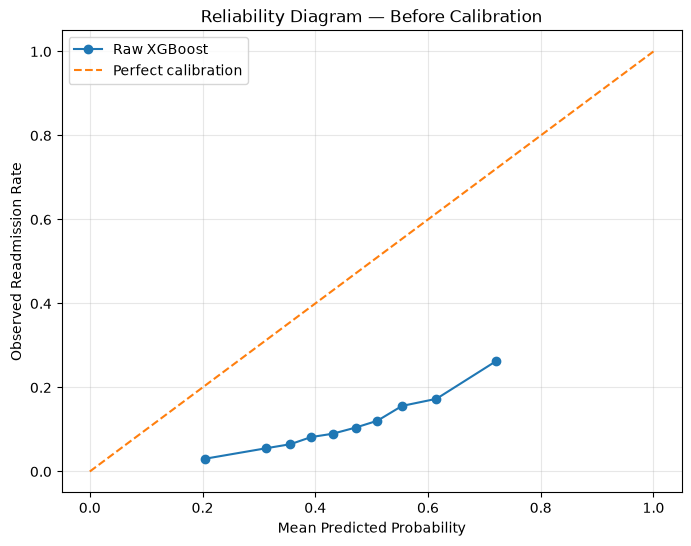

In [32]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

prob_true_raw, prob_pred_raw = calibration_curve(
    y_cal,
    cal_raw_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred_raw,
    prob_true_raw,
    marker="o",
    label="Raw XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Readmission Rate")
plt.title("Reliability Diagram — Before Calibration")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 10. Probability Calibration

The raw XGBoost model demonstrates useful discriminatory ability, but its
predicted probabilities are substantially higher than the observed 30-day
readmission rate.

This occurs partly because class weighting was used during model training to
address the strong class imbalance.

Two post-hoc calibration methods are evaluated:

1. Sigmoid (Platt) calibration
2. Isotonic regression

The calibration set is used exclusively to fit the probability calibrators.
The independent test set remains untouched until final model evaluation.

In [65]:
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression

# Rebuild calibration labels and probabilities from the current split so
# values left over from an earlier notebook run cannot become misaligned.
y_cal = y_train.loc[X_cal.index]
cal_raw_prob = base_model.predict_proba(X_cal)[:, 1]

# -------------------------------------------------------
# Sigmoid / Platt calibration
# -------------------------------------------------------

platt_calibrator = LogisticRegression()

platt_calibrator.fit(
    cal_raw_prob.reshape(-1, 1),
    y_cal
)

cal_platt_prob = platt_calibrator.predict_proba(
    cal_raw_prob.reshape(-1, 1)
)[:, 1]


# -------------------------------------------------------
# Isotonic calibration
# -------------------------------------------------------

isotonic_calibrator = IsotonicRegression(
    out_of_bounds="clip"
)

isotonic_calibrator.fit(
    cal_raw_prob,
    y_cal
)

cal_isotonic_prob = isotonic_calibrator.predict(
    cal_raw_prob
)

print("Calibration models fitted successfully.")

print("\nMean predicted probabilities")
print("--------------------------------")
print("Raw XGBoost :", round(cal_raw_prob.mean(), 4))
print("Platt       :", round(cal_platt_prob.mean(), 4))
print("Isotonic    :", round(cal_isotonic_prob.mean(), 4))
print("Actual rate :", round(y_cal.mean(), 4))

Calibration models fitted successfully.

Mean predicted probabilities
--------------------------------
Raw XGBoost : 0.4601
Platt       : 0.1143
Isotonic    : 0.1142
Actual rate : 0.1142


In [47]:
# Check separation between training, calibration and test patients

print("Training vs Test overlap:",
      len(set(train_groups) & set(test_groups)))

print("Available calibration variables:")
for name in [
    "cal_groups",
    "train_fit_groups",
    "X_cal",
    "y_cal",
    "cal_raw_prob"
]:
    if name in globals():
        value = globals()[name]
        print(name, ":", len(value))
    else:
        print(name, ": Not found")

Training vs Test overlap: 0
Available calibration variables:
cal_groups : Not found
train_fit_groups : Not found
X_cal : 16467
y_cal : 16467
cal_raw_prob : 16467


In [34]:
#Comparing calibration quality

calibration_results = pd.DataFrame({
    "Method": [
        "Raw XGBoost",
        "Platt",
        "Isotonic"
    ],

    "Brier Score": [
        brier_score_loss(y_cal, cal_raw_prob),
        brier_score_loss(y_cal, cal_platt_prob),
        brier_score_loss(y_cal, cal_isotonic_prob)
    ],

    "Log Loss": [
        log_loss(y_cal, cal_raw_prob),
        log_loss(y_cal, cal_platt_prob),
        log_loss(y_cal, cal_isotonic_prob)
    ],

    "ROC-AUC": [
        roc_auc_score(y_cal, cal_raw_prob),
        roc_auc_score(y_cal, cal_platt_prob),
        roc_auc_score(y_cal, cal_isotonic_prob)
    ],

    "PR-AUC": [
        average_precision_score(y_cal, cal_raw_prob),
        average_precision_score(y_cal, cal_platt_prob),
        average_precision_score(y_cal, cal_isotonic_prob)
    ]
})

calibration_results.round(4)

,Method,Brier Score,Log Loss,ROC-AUC,PR-AUC
0,Raw XGBoost,0.2208,0.6306,0.6773,0.2371
1,Platt,0.0959,0.3325,0.6773,0.2371
2,Isotonic,0.0951,0.3298,0.6802,0.2315


## 12. Reliability Diagrams After Calibration

The calibrated probabilities are compared with the raw XGBoost probabilities.

A well-calibrated model should produce predicted probabilities that closely
match the observed readmission frequency. Therefore, its reliability curve
should lie close to the diagonal reference line.

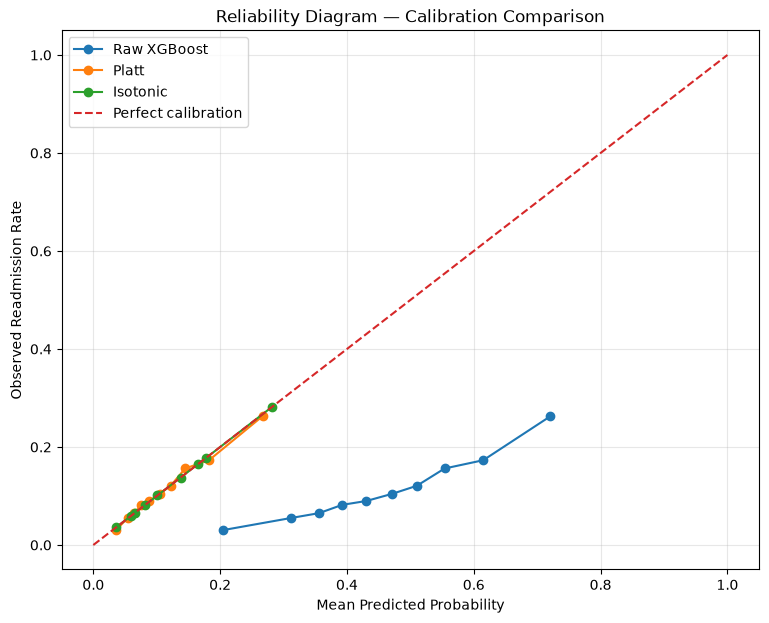

In [35]:
# Reliability diagram — Calibration comparison

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Raw model
raw_true, raw_pred = calibration_curve(
    y_cal,
    cal_raw_prob,
    n_bins=10,
    strategy="quantile"
)

# Platt calibration
platt_true, platt_pred = calibration_curve(
    y_cal,
    cal_platt_prob,
    n_bins=10,
    strategy="quantile"
)

# Isotonic calibration
iso_true, iso_pred = calibration_curve(
    y_cal,
    cal_isotonic_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(9, 7))

plt.plot(
    raw_pred,
    raw_true,
    marker="o",
    label="Raw XGBoost"
)

plt.plot(
    platt_pred,
    platt_true,
    marker="o",
    label="Platt"
)

plt.plot(
    iso_pred,
    iso_true,
    marker="o",
    label="Isotonic"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Readmission Rate")
plt.title("Reliability Diagram — Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [36]:
# Expected Calibration Error (ECE) Calculation

import numpy as np


def expected_calibration_error(y_true, probabilities, n_bins=10):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(
        probabilities,
        bin_edges[1:-1],
        right=True
    )

    ece = 0.0

    for bin_id in range(n_bins):
        mask = bin_ids == bin_id

        if mask.sum() == 0:
            continue

        mean_probability = probabilities[mask].mean()
        observed_rate = y_true[mask].mean()

        ece += (
            mask.mean()
            * abs(mean_probability - observed_rate)
        )

    return ece


raw_ece = expected_calibration_error(
    y_cal,
    cal_raw_prob
)

platt_ece = expected_calibration_error(
    y_cal,
    cal_platt_prob
)

isotonic_ece = expected_calibration_error(
    y_cal,
    cal_isotonic_prob
)

print("EXPECTED CALIBRATION ERROR")
print("--------------------------")
print("Raw XGBoost :", round(raw_ece, 4))
print("Platt       :", round(platt_ece, 4))
print("Isotonic    :", round(isotonic_ece, 4))

EXPECTED CALIBRATION ERROR
--------------------------
Raw XGBoost : 0.3428
Platt       : 0.006
Isotonic    : 0.0


## 14. Final Calibration Method Selection

Platt scaling was selected as the final probability calibration method.

Although isotonic regression achieved slightly lower calibration error on the
calibration dataset, isotonic regression is a more flexible non-parametric
method and may fit the calibration sample too closely.

Platt scaling produced excellent calibration while retaining the ranking
performance of the underlying XGBoost model.

The final calibration method was selected **before evaluating the untouched
test set** to prevent test-set information from influencing model development.

In [67]:
final_calibrator = platt_calibrator

print("Final calibration method: Platt scaling")
print("Calibration-set ECE:", round(platt_ece, 4))

Final calibration method: Platt scaling
Calibration-set ECE: 0.006


In [68]:
# Evaluate the performance of raw and calibrated probabilities on the test set

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

# --------------------------------------------------
# 1. Raw probabilities from the base XGBoost pipeline
# --------------------------------------------------

test_raw_prob = base_model.predict_proba(X_test)[:, 1]


# --------------------------------------------------
# 2. Apply fitted Platt calibration model
# --------------------------------------------------

test_calibrated_prob = final_calibrator.predict_proba(
    test_raw_prob.reshape(-1, 1)
)[:, 1]


# --------------------------------------------------
# 3. Evaluate raw vs calibrated probabilities
# --------------------------------------------------

test_results = pd.DataFrame({

    "Method": [
        "Raw XGBoost",
        "Platt Calibrated"
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, test_raw_prob),
        roc_auc_score(y_test, test_calibrated_prob)
    ],

    "PR-AUC": [
        average_precision_score(y_test, test_raw_prob),
        average_precision_score(y_test, test_calibrated_prob)
    ],

    "Brier Score": [
        brier_score_loss(y_test, test_raw_prob),
        brier_score_loss(y_test, test_calibrated_prob)
    ],

    "Log Loss": [
        log_loss(y_test, test_raw_prob),
        log_loss(y_test, test_calibrated_prob)
    ],

    "ECE": [
        expected_calibration_error(
            y_test,
            test_raw_prob
        ),

        expected_calibration_error(
            y_test,
            test_calibrated_prob
        )
    ]
})

test_results.round(4)

,Method,ROC-AUC,PR-AUC,Brier Score,Log Loss,ECE
0,Raw XGBoost,0.6652,0.2229,0.2215,0.6345,0.3439
1,Platt Calibrated,0.6652,0.2229,0.0971,0.3374,0.0044


In [71]:
# Probability Calibration Analysis

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

results = []

for threshold in thresholds:

    y_pred = (test_calibrated_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Patients Flagged": int(y_pred.sum()),
        "True Positives": int(tp),
        "False Positives": int(fp)
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(4))

,Threshold,Precision,Recall,F1-score,Patients Flagged,True Positives,False Positives
0,0.05,0.1224,0.9640,0.2172,18153,2222,15931
1,0.10,0.1635,0.6733,0.2631,9494,1552,7942
2,0.15,0.2176,0.4104,0.2844,4347,946,3401
3,0.20,0.2666,0.2503,0.2582,2164,577,1587
4,0.25,0.3276,0.1332,0.1894,937,307,630
5,0.30,0.4016,0.0672,0.1152,386,155,231
6,0.40,0.5000,0.0056,0.0112,26,13,13
7,0.50,0.0000,0.0000,0.0000,0,0,0


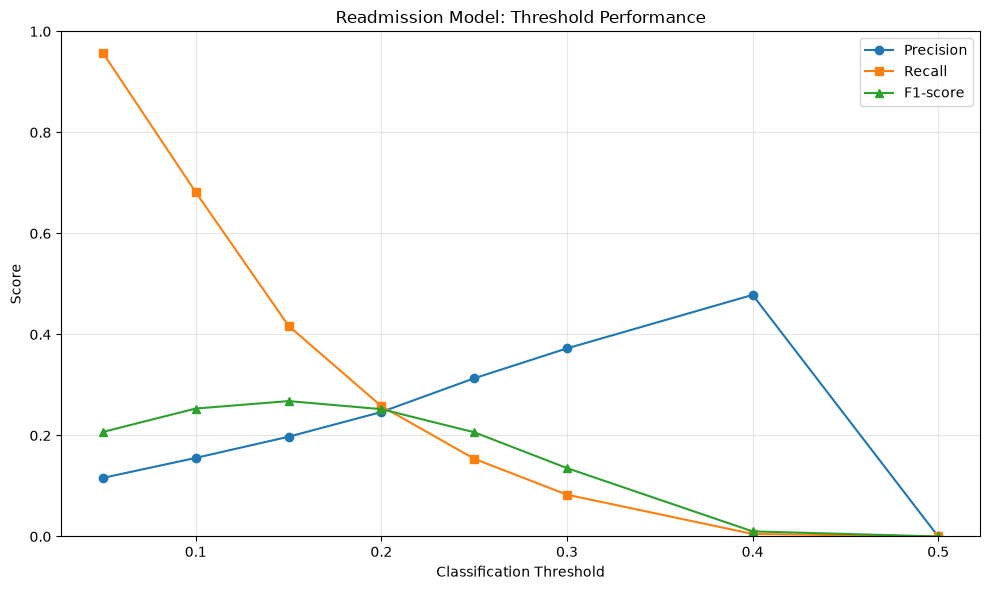

In [44]:
# Threshold Performance Visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1-score"],
    marker="^",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Readmission Model: Threshold Performance")

plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

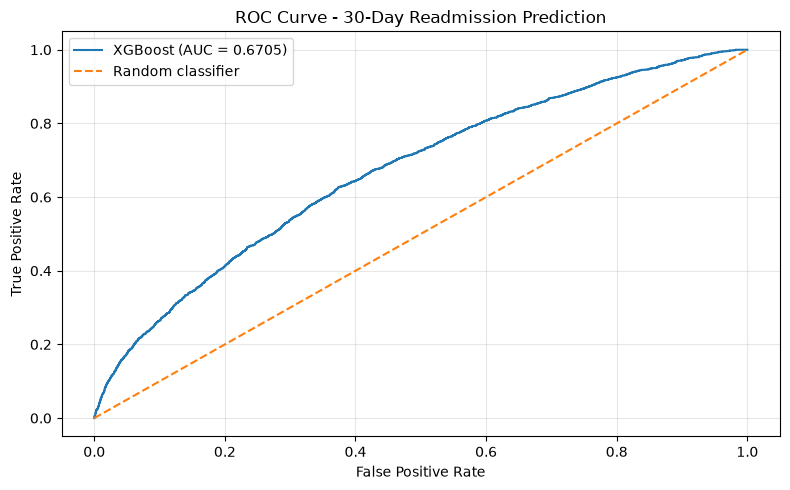

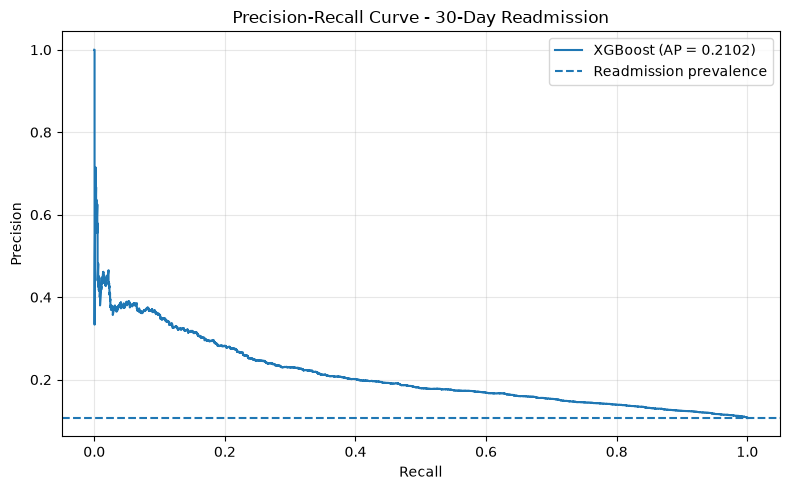

In [45]:
# ROC and Precision-Recall Curve Visualization
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# ROC curve
fpr, tpr, _ = roc_curve(y_test, test_calibrated_prob)
roc_auc = roc_auc_score(y_test, test_calibrated_prob)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"XGBoost (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - 30-Day Readmission Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Precision-Recall curve
precision_curve, recall_curve, _ = precision_recall_curve(
    y_test, test_calibrated_prob
)

average_precision = average_precision_score(
    y_test, test_calibrated_prob
)

plt.figure(figsize=(8, 5))
plt.plot(
    recall_curve,
    precision_curve,
    label=f"XGBoost (AP = {average_precision:.4f})"
)

plt.axhline(
    y=float(y_test.mean()),
    linestyle="--",
    label="Readmission prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - 30-Day Readmission")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

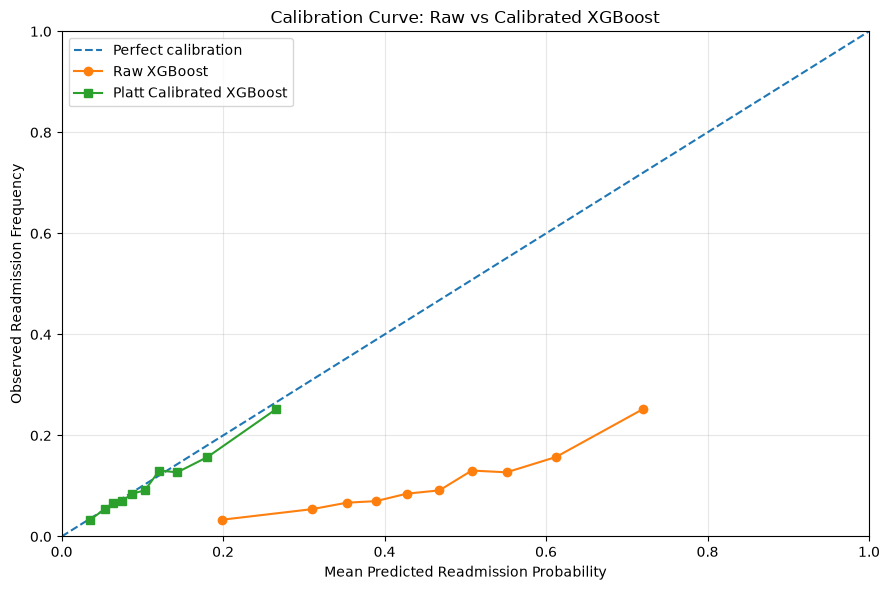

In [46]:
# Calibration Curve Visualization
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Calculate observed readmission rates and mean predicted risks
raw_observed, raw_predicted = calibration_curve(
    y_test,
    test_raw_prob,
    n_bins=10,
    strategy="quantile"
)

cal_observed, cal_predicted = calibration_curve(
    y_test,
    test_calibrated_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(9, 6))

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

# Original model
plt.plot(
    raw_predicted,
    raw_observed,
    marker="o",
    label="Raw XGBoost"
)

# Calibrated model
plt.plot(
    cal_predicted,
    cal_observed,
    marker="s",
    label="Platt Calibrated XGBoost"
)

plt.xlabel("Mean Predicted Readmission Probability")
plt.ylabel("Observed Readmission Frequency")
plt.title("Calibration Curve: Raw vs Calibrated XGBoost")

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [39]:
# Final test-set probability check

print("FINAL TEST-SET PROBABILITY CHECK")
print("--------------------------------")

print(
    "Actual readmission rate :",
    round(y_test.mean(), 4)
)

print(
    "Raw mean probability    :",
    round(test_raw_prob.mean(), 4)
)

print(
    "Calibrated mean probability:",
    round(test_calibrated_prob.mean(), 4)
)

print(
    "\nMinimum calibrated probability:",
    round(test_calibrated_prob.min(), 4)
)

print(
    "Maximum calibrated probability:",
    round(test_calibrated_prob.max(), 4)
)

FINAL TEST-SET PROBABILITY CHECK
--------------------------------
Actual readmission rate : 0.1067
Raw mean probability    : 0.4539
Calibrated mean probability: 0.1128

Minimum calibrated probability: 0.0141
Maximum calibrated probability: 0.4536


In [40]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Recompute calibrated test probabilities so this cell does not depend on a
# separately executed evaluation cell.
test_raw_prob = base_model.predict_proba(X_test)[:, 1]
test_calibrated_prob = final_calibrator.predict_proba(
    test_raw_prob.reshape(-1, 1)
)[:, 1]

# Classification threshold for this initial evaluation
threshold = 0.50

# Convert calibrated probabilities into binary predictions
y_pred = (test_calibrated_prob >= threshold).astype(int)

# Calculate classification metrics
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display results
print("MODEL CLASSIFICATION PERFORMANCE")
print("--------------------------------")
print("Threshold:", threshold)
print("Readmission prevalence:", round(y_test.mean(), 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

MODEL CLASSIFICATION PERFORMANCE
--------------------------------
Threshold: 0.5
Readmission prevalence: 0.1067
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion Matrix:
[[18002     0]
 [ 2151     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     18002
           1       0.00      0.00      0.00      2151

    accuracy                           0.89     20153
   macro avg       0.45      0.50      0.47     20153
weighted avg       0.80      0.89      0.84     20153



In [41]:
# Save the Platt calibrator to a file using joblib

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

calibrator_path = MODEL_DIR / "platt_calibrator.joblib"

joblib.dump(platt_calibrator, calibrator_path)

print(f"Platt calibrator saved to: {calibrator_path}")

Platt calibrator saved to: ..\models\platt_calibrator.joblib


In [42]:
# Load the saved Platt calibrator and make a prediction on a test raw probability

loaded_calibrator = joblib.load(
    "../models/platt_calibrator.joblib"
)

test_raw_probability = 0.54981774

test_calibrated_probability = loaded_calibrator.predict_proba(
    [[test_raw_probability]]
)[:, 1][0]

print("Calibrator loaded successfully.")
print("Raw probability:", test_raw_probability)
print("Calibrated probability:", test_calibrated_probability)

Calibrator loaded successfully.
Raw probability: 0.54981774
Calibrated probability: 0.14233367794828497
